In [1]:
import numpy as np
# import lll_sp
from fpylll import *
from copy import deepcopy 
from sage.all import *
from sage.stats.distributions.discrete_gaussian_integer import \
    DiscreteGaussianDistributionIntegerSampler
import time

#!/usr/bin/env sage -python

import re
import ast
import sys

from sage.all import matrix, ZZ
from fpylll import IntegerMatrix
import subprocess
import tempfile
import os
from fpylll import IntegerMatrix

import subprocess
from fpylll import IntegerMatrix

def flatter_interface(B):
    n, m = B.nrows, B.ncols

    # Explicit FPLLL serialization
    input_text = "[\n"
    for i in range(n):
        input_text += "[" + " ".join(str(B[i, j]) for j in range(m)) + "]\n"
    input_text += "]\n"

    result = subprocess.run(
        ["flatter"],
        input=input_text,
        capture_output=True,
        text=True,
        check=False
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"Flatter failed ({result.returncode}):\n"
            f"{result.stderr}"
        )

    # Parse the reduced basis
    return IntegerMatrix.from_matrix(
        [
            [int(x) for x in line.strip().strip("[]").split()]
            for line in result.stdout.splitlines()
            if line.strip().strip("[]").strip()
        ],
        int_type="mpz"
    )

def load_lattice(filename):
    with open(filename, "r") as f:
        text = f.read().strip()

    # Convert fplll notation into a Python list of lists.
    # For example: [ [1 2] [3 4] ] -> [[1, 2], [3, 4]]
    rows = re.findall(r"\[([^\[\]]+)\]", text)

    if not rows:
        raise ValueError("No matrix rows found")

    data = [
        [ZZ(x) for x in row.replace(",", " ").split()]
        for row in rows
    ]

    B = matrix(ZZ, data)

    # Convert to fpylll.IntegerMatrix.
    A = IntegerMatrix(B.nrows(), B.ncols())

    for i in range(B.nrows()):
        for j in range(B.ncols()):
            A[i, j] = int(B[i, j])

    return A


# ------------------------------------------------------------
# Hot-swappable coefficient samplers
# ------------------------------------------------------------

def discrete_gaussian_sampler(sigma=3.0):
    D = DiscreteGaussianDistributionIntegerSampler(sigma=sigma)
    return lambda: ZZ(D())


def centered_binomial_sampler(eta=2):
    return lambda: ZZ(
        sum(randint(0, 1) for _ in range(eta))
        - sum(randint(0, 1) for _ in range(eta))
    )


def uniform_sampler(bound=3):
    return lambda: ZZ(randint(-bound, bound))


# ------------------------------------------------------------
# Sample a polynomial
# ------------------------------------------------------------

def sample_poly(R, n, sampler):
    """
    Sample sum_i a_i*x^i, where sampler() returns one integer coefficient.
    """
    return R([sampler() for _ in range(n)])


# ------------------------------------------------------------
# Row-circulant multiplication matrix
# ------------------------------------------------------------

def multiplication_matrix_rows(h, n):
    """
    Return H such that for a ROW coefficient vector v,

        v * H

    is the coefficient vector of v(x)*h(x) mod (x^n - 1).

    The i-th row is coeffs(x^i h).
    """
    R = h.parent()
    x = R.gen()

    rows = []

    for i in range(n):
        hi = (x**i) * h
        rows.append([
            ZZ(hi[j]) for j in range(n)
        ])

    return matrix(ZZ, rows)


# ------------------------------------------------------------
# NTRU lattice
# ------------------------------------------------------------

def ntru_lattice(n,
                 q,
                 f_sampler=None,
                 g_sampler=None,
                 sigma=3.0):
    """
    Generate a row-basis NTRU lattice for

        R_q = Z_q[x] / (x^n - 1).

    We sample f,g and define

        h = g / f  mod q.

    Returns
        B : 2n x 2n integer row basis
        f : secret polynomial over ZZ
        g : secret polynomial over ZZ
        h : public polynomial over Z/qZ

    The lattice contains a representative corresponding to (f,g).

    The q-ary basis vectors (0, q e_i) are placed first.

    f_sampler and g_sampler are callables returning integer coefficients.
    """

    if f_sampler is None:
        f_sampler = discrete_gaussian_sampler(sigma)

    if g_sampler is None:
        g_sampler = discrete_gaussian_sampler(sigma)

    # Integer polynomial ring for keeping the secrets
    PZ.<X> = PolynomialRing(ZZ)

    # Ring modulo q and X^n - 1
    Pq.<x> = PolynomialRing(Zmod(q))
    Rq.<xx> = Pq.quotient(x**n - 1)

    # --------------------------------------------------------
    # Find an invertible f
    # --------------------------------------------------------

    while True:
        fZ = sample_poly(PZ, n, f_sampler)
        f = Rq(fZ)

        try:
            f_inv = f**(-1)
            break
        except (ZeroDivisionError, ArithmeticError, ValueError):
            pass

    # Sample g
    gZ = sample_poly(PZ, n, g_sampler)
    g = Rq(gZ)

    # Public NTRU element
    h = g * f_inv

    # --------------------------------------------------------
    # Multiplication-by-h matrix
    # --------------------------------------------------------

    Hmod = []

    for i in range(n):
        hi = xx**i * h

        Hmod.append([
            ZZ(hi[j]) for j in range(n)
        ])

    # Center representatives modulo q
    def center(a):
        a = ZZ(a) % q
        return a if a <= q // 2 else a - q

    H = matrix(ZZ, [
        [center(a) for a in row]
        for row in Hmod
    ])

    # --------------------------------------------------------
    # Row basis, q-ary vectors first
    #
    #         [ 0   qI ]
    #     B = [        ]
    #         [ I    H ]
    # --------------------------------------------------------

    I = identity_matrix(ZZ, n)
    Z = zero_matrix(ZZ, n)

    B = block_matrix(ZZ, [
        [Z, q * I],
        [I, H]
    ])

    return B, fZ, gZ, h

from fpylll import IntegerMatrix, GSO, FPLLL
from sandpile_mpfr import SandpileSeq


Lovasz swaps: 83126
Siegel swaps: 1533


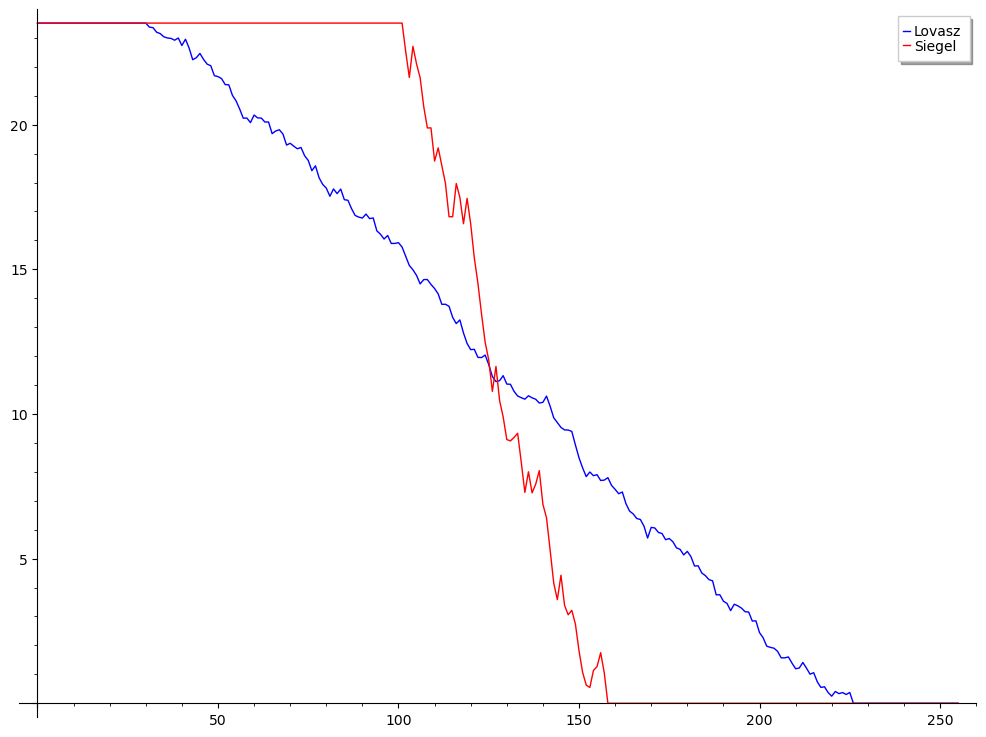

In [2]:
from fpylll import IntegerMatrix, GSO, FPLLL
from sandpile_mpfr import SandpileSeq
from sage.all import RealField, log, list_plot

prec = 212
FPLLL.set_precision(prec)
R = RealField(prec)

B = ntru_lattice(
    128, 3457,
    f_sampler=discrete_gaussian_sampler(1.0),
    g_sampler=discrete_gaussian_sampler(1.0),
)[0]

M = GSO.Mat(IntegerMatrix.from_matrix(B), float_type="mpfr")
M.update_gso()

lovasz = SandpileSeq(
    M, condition="lovasz", delta="0.95", seed=42
)

siegel = SandpileSeq(
    M, condition="siegel", delta="0.6999", seed=42
)

lovasz.run()
siegel.run()

print("Lovasz swaps:", lovasz.swaps)
print("Siegel swaps:", siegel.swaps)

# Recover high-precision profiles
r_lovasz = [R(x) for x in lovasz.profile()]
r_siegel = [R(x) for x in siegel.profile()]

# Squared GSO profile in logarithmic scale
p_lovasz = [log(x, 2) for x in r_lovasz]
p_siegel = [log(x, 2) for x in r_siegel]

p = list_plot(
    p_lovasz, plotjoined=True,
    color="blue", legend_label="Lovasz"
)
p += list_plot(
    p_siegel, plotjoined=True,
    color="red", legend_label="Siegel"
)

p.show(figsize=10)

In [3]:
from sandpile_mpfr import (
    SandpileSeq,
    gso_mu_entry,
    gso_swap_is_valid,
)

print("Imports successful")

Imports successful
